# Коты Шрёдингера — интерактивный ноутбук

- **кот** умирает, если банка разбита
- **кошка** умирает, если банка цела — условия противоположные
- **котёнок** рождается, только если оба родителя живы

Что внутри:
1. Схема и её параметры.
2. Пошагово на сферах Блоха: как кубиты запутываются и «исчезают» с поверхности сферы.
3. Заглядываем в закрытую коробку.
4. Идеальный симулятор.
5. Симуляторы с ошибками: модель реального чипа IBM и свой шум с ручками.
6. Как шум выглядит на сфере Блоха.
7. Запуск на настоящем IBM (выключен по умолчанию).

Запускай ячейки сверху вниз (`Shift+Enter`). Места, где стоит что-то поменять, помечены ✏️.

## 0. Подготовка

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.quantum_info import Statevector, DensityMatrix, partial_trace
from qiskit.visualization import plot_bloch_multivector, plot_state_qsphere
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

KEYS = [format(i, "03b") for i in range(8)]          # котёнок, кошка, кот (порядок Qiskit)

def describe(bits3, sep="\n"):
    kit, she, cat = bits3
    return sep.join([f"кот {'жив' if cat == '1' else 'мёртв'}",
                     f"кошка {'жива' if she == '1' else 'мертва'}",
                     f"котёнок {'есть' if kit == '1' else 'нет'}"])

def impossible(bits3):
    # котёнок есть, но хотя бы один родитель мёртв
    kit, she, cat = bits3
    return kit == "1" and not (she == "1" and cat == "1")

def plot_counts(results, title=""):
    # results: {подпись: counts} — несколько наборов рядом
    names = list(results)
    w = 0.8 / len(names)
    fig, ax = plt.subplots(figsize=(13, 5))
    for i, name in enumerate(names):
        c = results[name]
        total = sum(c.values())
        vals = [c.get(k, 0) / total for k in KEYS]
        ax.bar(np.arange(8) + (i - (len(names) - 1) / 2) * w, vals, w, label=name)
    ax.set_xticks(range(8))
    ax.set_xticklabels([describe(k) for k in KEYS], fontsize=8.5)
    for i, k in enumerate(KEYS):
        if impossible(k):
            ax.get_xticklabels()[i].set_color("#A32D2D")
    ax.set_ylabel("доля запусков")
    ax.set_title(title)
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

def summary(counts):
    total = sum(counts.values())
    good = sum(v for k, v in counts.items() if k in ("001", "010"))
    imp = sum(v for k, v in counts.items() if impossible(k))
    born = sum(v for k, v in counts.items() if k[0] == "1")
    return f"правильные истории {good/total:.1%},  котёнок родился {born/total:.1%},  из них невозможных {imp/total:.1%}"

from qiskit.visualization.bloch import Bloch
from qiskit.quantum_info import SparsePauliOp

def bloch_vector(state, i):
    # вектор Блоха кубита i: (⟨X⟩, ⟨Y⟩, ⟨Z⟩) его собственной (редуцированной) матрицы плотности
    n = state.num_qubits
    rho = DensityMatrix(state) if n == 1 else partial_trace(state, [j for j in range(n) if j != i])
    return [rho.expectation_value(SparsePauliOp(p)).real for p in "XYZ"]

def bloch_row(items, title=""):
    # items: список (подпись, вектор Блоха) — рисуем сферы в один ряд
    fig = plt.figure(figsize=(3.0 * len(items), 3.7))
    for k, (label, v) in enumerate(items):
        ax = fig.add_subplot(1, len(items), k + 1, projection="3d")
        b = Bloch(axes=ax, font_size=11)
        if np.linalg.norm(v) > 1e-3:          # нулевую стрелку не рисуем — только точку в центре
            b.add_vectors(v)
        else:
            b.add_points([0, 0, 0])
        b.render(title=f"{label}\nдлина {np.linalg.norm(v):.2f}")
    fig.suptitle(title, fontsize=13)
    plt.show()

def bloch_all(state, names, title=""):
    bloch_row([(names[i], bloch_vector(state, i)) for i in range(state.num_qubits)], title)

print("Готово")

Готово


## 1. Схема

`MODE = "shared"` — один общий атом: судьбы кота и кошки противоположны, котёнок невозможен.
`MODE = "independent"` — у каждого свой атом: котёнок рождается с вероятностью 25% (при `THETA = 90`).

`THETA` — угол поворота атома: 90° — распад 50/50, меньше — атом распадается реже.

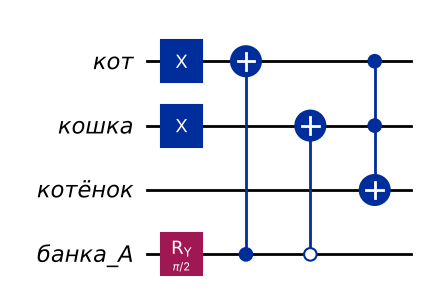

In [2]:
MODE = "shared"        # ✏️ "shared" или "independent"
THETA = 90             # ✏️ угол атома в градусах

def build_cats(mode=MODE, theta_deg=THETA, upto=None):
    # upto — сколько шагов схемы выполнить (для пошагового просмотра); None — все
    th = math.radians(theta_deg)
    regs = [QuantumRegister(1, "кот"), QuantumRegister(1, "кошка"),
            QuantumRegister(1, "котёнок"), QuantumRegister(1, "банка_А")]
    if mode == "independent":
        regs.append(QuantumRegister(1, "банка_Б"))
    qc = QuantumCircuit(*regs)
    CAT, SHE, KIT, VA = 0, 1, 2, 3
    steps = [
        lambda: (qc.x(CAT), qc.x(SHE)),                      # 1: коты живы
        lambda: (qc.ry(th, VA), mode == "independent" and qc.ry(th, 4)),   # 2: атомы
        lambda: qc.cx(VA, CAT),                               # 3: банка А разбита -> кот умирает
        lambda: (qc.cx(VA, SHE, ctrl_state=0) if mode == "shared" else qc.cx(4, SHE)),  # 4: кошка
        lambda: qc.ccx(CAT, SHE, KIT),                        # 5: котёнок
    ]
    for f in steps[: (len(steps) if upto is None else upto)]:
        f()
    return qc

def measured(qc):
    m = qc.copy()
    m.add_register(ClassicalRegister(3, "c"))
    m.measure([0, 1, 2], [0, 1, 2])
    return m

cats = build_cats()
cats.draw("mpl")

## 2. Пошагово на сферах Блоха

У каждого кубита своя сфера. Напомню: «жив» = |1⟩ = стрелка **вниз**, «мёртв» = |0⟩ = стрелка вверх. Пока кубит не запутан, стрелка лежит **на поверхности** сферы, её длина 1. Как только он запутывается с другими, у него по отдельности больше нет определённого направления: стрелка **укорачивается**, а у максимально запутанного кубита исчезает совсем — точка в центре шара.

Смотри, на каком шаге «пропадают» кот и кошка, и что происходит с котёнком.

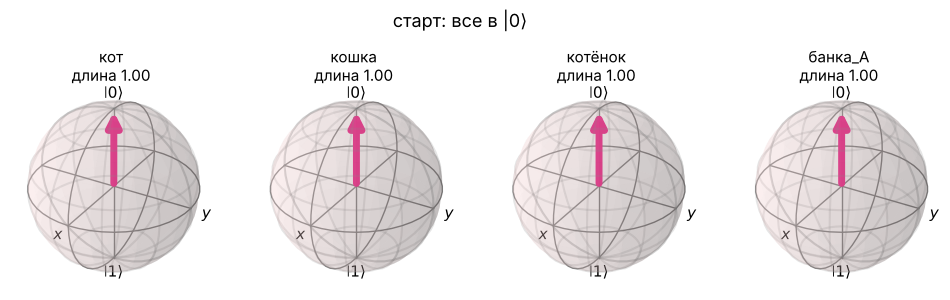

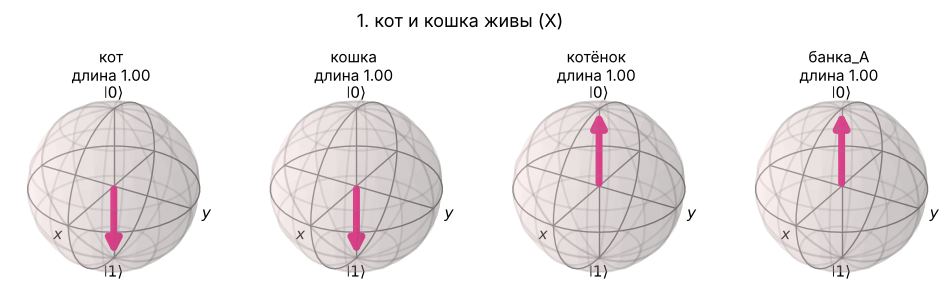

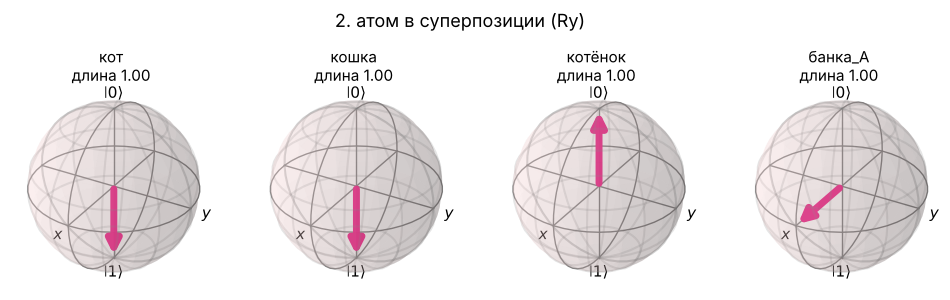

/usr/local/lib/python3.13/dist-packages/qiskit/visualization/bloch.py:666: RuntimeWarning: invalid value encountered in divide
  if any(abs(dist - dist[0]) / dist[0] > 1e-12):


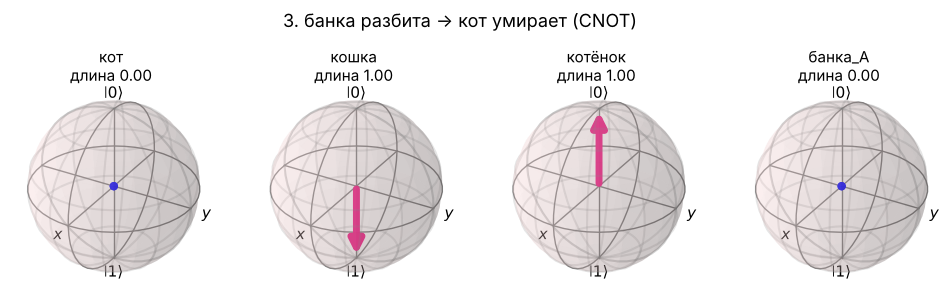

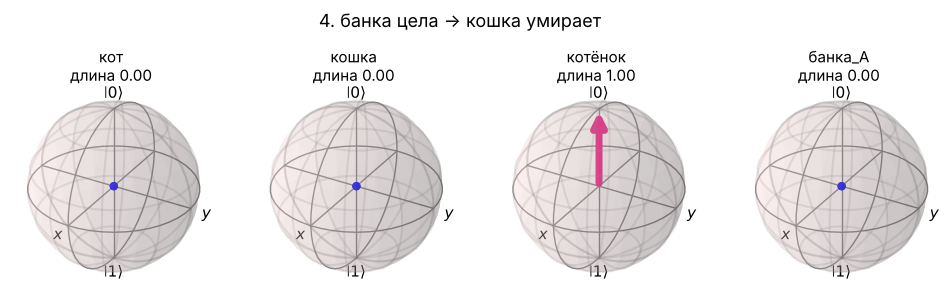

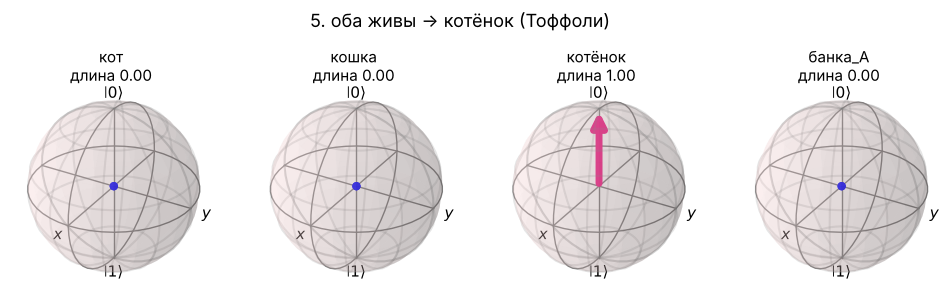

In [3]:
STEP_NAMES = ["старт: все в |0⟩",
              "1. кот и кошка живы (X)",
              "2. атом в суперпозиции (Ry)",
              "3. банка разбита → кот умирает (CNOT)",
              "4. банка цела → кошка умирает",
              "5. оба живы → котёнок (Тоффоли)"]

for k, name in enumerate(STEP_NAMES):
    qc_k = build_cats(upto=k)
    names = [reg.name for reg in qc_k.qregs]
    bloch_all(Statevector(qc_k), names, name)

**Что видно:**
- после шага 2 атом лёг на экватор — он в суперпозиции, но ещё ни с кем не связан, стрелка полной длины;
- на шаге 3 CNOT запутал кота с банкой — **стрелки обоих исчезли**: по отдельности у них нет состояния, только общее;
- на шаге 4 к ним присоединилась кошка;
- в режиме `shared` котёнок на шаге 5 так и остался на северном полюсе |0⟩ — полноценная стрелка, он чистый и ни с кем не запутан.

Поменяй `MODE` на `"independent"` в разделе 1, перезапусти ячейки — котёнок тоже «уйдёт в центр», потому что теперь он часть общей запутанной истории.

### Вся система целиком: Q-сфера

Сферы Блоха не показывают корреляции. Q-сфера рисует **всё состояние сразу**: каждая точка — одно базисное состояние всей системы, размер точки — вероятность, цвет — фаза. Видны две «истории», между которыми кот находится в суперпозиции.

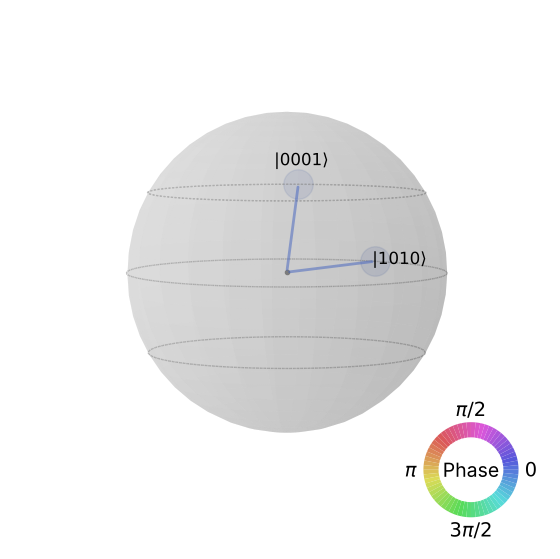

In [4]:
plot_state_qsphere(Statevector(cats), figsize=(7, 7))

## 3. Заглядываем в закрытую коробку

In [5]:
sv = Statevector(cats)
display(sv.draw("latex"))

for bits, p in sorted(sv.probabilities_dict().items()):
    if p > 1e-9:
        print(f"P = {p:.3f}:  {describe(bits[-3:], ', ')}   (банки: {bits[:-3]})")

print()
for idx, name in [(0, "кот"), (1, "кошка"), (2, "котёнок")]:
    rho = partial_trace(sv, [i for i in range(sv.num_qubits) if i != idx])
    print(f"{name:8s}  жив с вероятностью {rho.data[1,1].real:.3f},  чистота {rho.purity().real:.3f}")

<IPython.core.display.Latex object>

P = 0.500:  кот жив, кошка мертва, котёнок нет   (банки: 0)
P = 0.500:  кот мёртв, кошка жива, котёнок нет   (банки: 1)

кот       жив с вероятностью 0.500,  чистота 0.500
кошка     жив с вероятностью 0.500,  чистота 0.500
котёнок   жив с вероятностью 0.000,  чистота 1.000


Чистота 1 — кубит в определённом состоянии и ни с кем не запутан. Чистота 0.5 — максимальная смесь: всё, что о нём известно, «размазано» по корреляциям с остальными.

## 4. Идеальный симулятор

правильные истории 100.0%,  котёнок родился 0.0%,  из них невозможных 0.0%


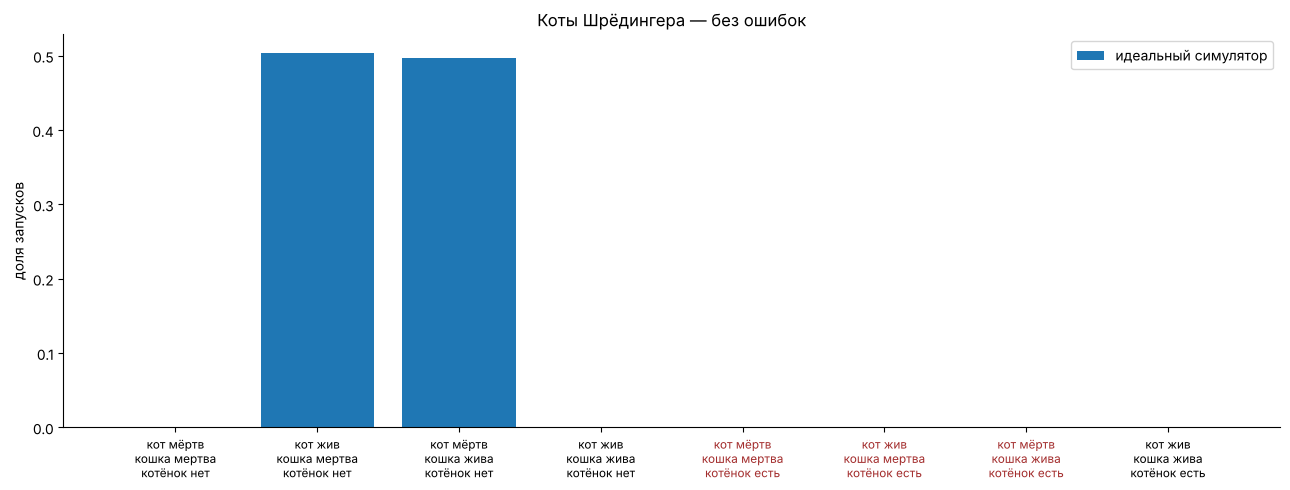

In [6]:
SHOTS = 4000          # ✏️

ideal_sim = AerSimulator()
ideal = ideal_sim.run(transpile(measured(cats), ideal_sim), shots=SHOTS).result().get_counts()
print(summary(ideal))
plot_counts({"идеальный симулятор": ideal}, "Коты Шрёдингера — без ошибок")

Красным подписаны **физически невозможные** истории: котёнок есть, хотя хотя бы один родитель мёртв. На идеальном симуляторе их нет.

## 5. Симуляторы с ошибками

### 5.1. Модель реального чипа IBM

`AerSimulator.from_backend(FakeTorino())` берёт из снимка калибровки реального процессора Torino всё сразу: ошибки каждого гейта на каждом кубите, ошибки считывания, времена T1/T2 и карту связей. Схема при этом транспилируется так же, как для настоящего чипа, — с маршрутизацией и разложением Тоффоли.

после транспиляции: глубина 54, двухкубитных гейтов 14


идеал:      правильные истории 100.0%,  котёнок родился 0.0%,  из них невозможных 0.0%
FakeTorino: правильные истории 92.1%,  котёнок родился 4.4%,  из них невозможных 3.5%


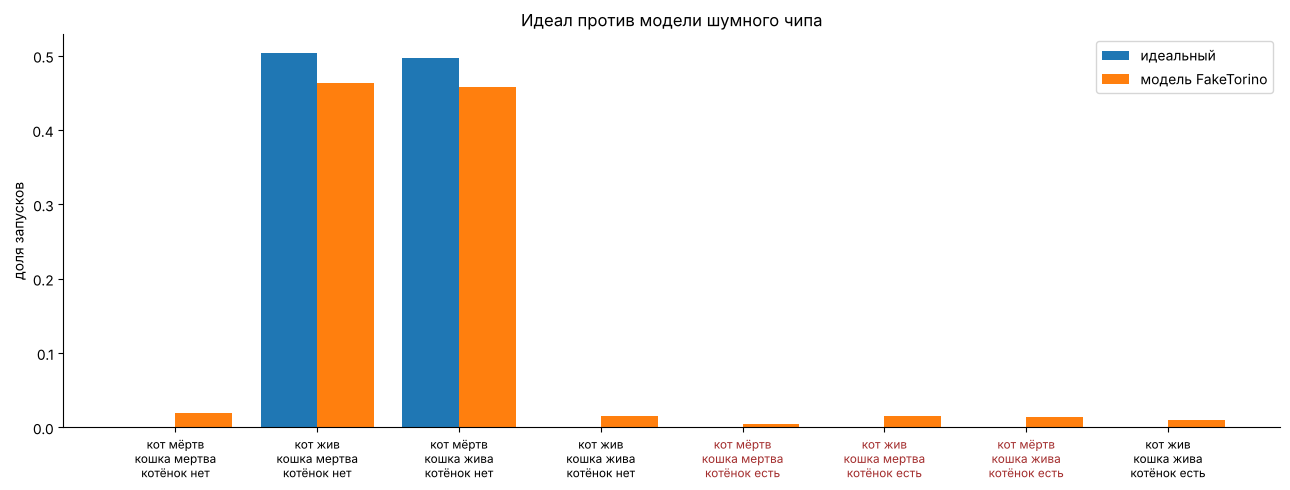

In [7]:
from qiskit_ibm_runtime.fake_provider import FakeTorino

fake_backend = FakeTorino()
noisy_sim = AerSimulator.from_backend(fake_backend)
tcats = transpile(measured(cats), noisy_sim, optimization_level=1, seed_transpiler=1)
ops = tcats.count_ops()
print(f"после транспиляции: глубина {tcats.depth()}, двухкубитных гейтов {ops.get('cz', 0) + ops.get('cx', 0) + ops.get('ecr', 0)}")

fake_counts = noisy_sim.run(tcats, shots=SHOTS).result().get_counts()
print("идеал:     ", summary(ideal))
print("FakeTorino:", summary(fake_counts))
plot_counts({"идеальный": ideal, "модель FakeTorino": fake_counts}, "Идеал против модели шумного чипа")

### 5.2. Свой шум — с ручками

Здесь шум задаётся вручную, и его можно крутить:
- `P1` — вероятность ошибки на однокубитном гейте,
- `P2` — на двухкубитном (CNOT),
- `P_READ` — вероятность прочитать бит неправильно.

Модель — **деполяризующий шум**: с вероятностью p после гейта кубит «забывает» своё состояние и превращается в случайное. Реальный шум сложнее, но для интуиции этого хватает.

Для сравнения: у современных чипов IBM типично P1 ≈ 0.0003, P2 ≈ 0.003–0.01, P_READ ≈ 0.01–0.02.

мой шум: правильные истории 89.9%,  котёнок родился 4.3%,  из них невозможных 3.6%


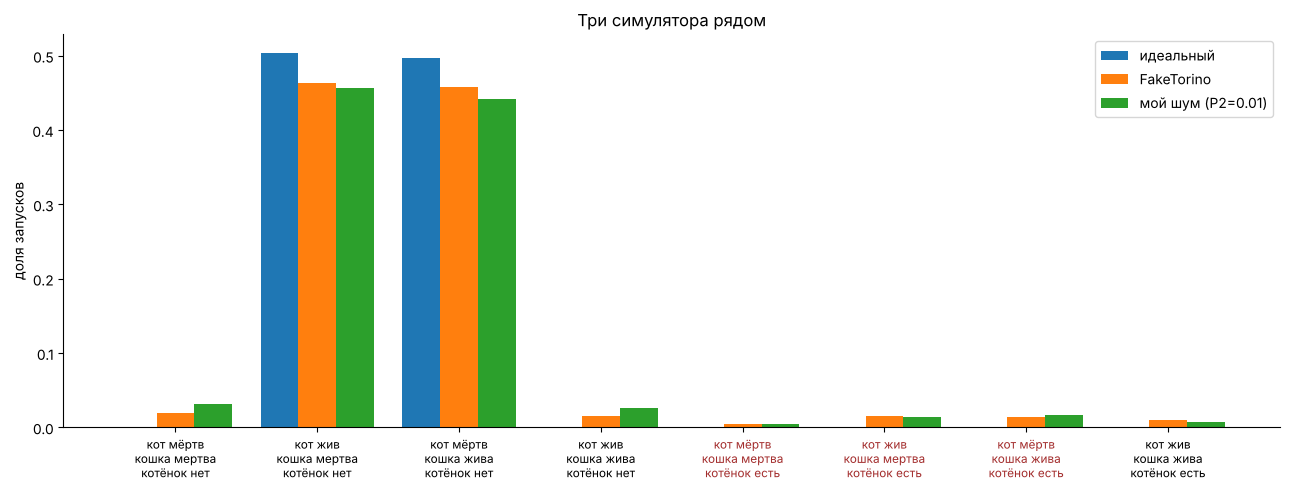

In [8]:
P1 = 0.001       # ✏️ ошибка однокубитного гейта
P2 = 0.01        # ✏️ ошибка CNOT
P_READ = 0.02    # ✏️ ошибка считывания

def make_noise(p1, p2, p_read):
    nm = NoiseModel()
    if p1 > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["x", "sx", "rz", "ry", "h"])
    if p2 > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])
    if p_read > 0:
        nm.add_all_qubit_readout_error(ReadoutError([[1 - p_read, p_read], [p_read, 1 - p_read]]))
    return nm

BASIS = ["x", "sx", "rz", "ry", "h", "cx"]
my_sim = AerSimulator(noise_model=make_noise(P1, P2, P_READ))
my_counts = my_sim.run(transpile(measured(cats), basis_gates=BASIS, optimization_level=1),
                       shots=SHOTS).result().get_counts()
print("мой шум:", summary(my_counts))
plot_counts({"идеальный": ideal, "FakeTorino": fake_counts, f"мой шум (P2={P2})": my_counts},
            "Три симулятора рядом")

### 5.3. Как невозможные котята зависят от качества CNOT

Прогоним схему при разных ошибках CNOT и посмотрим, как растёт доля физически невозможных историй и падает доля правильных.

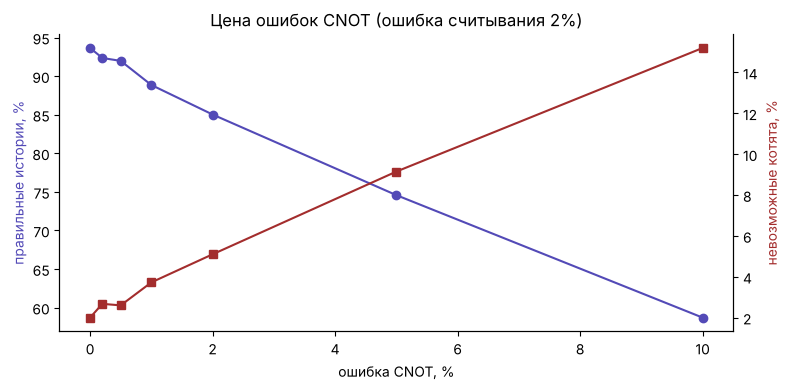

In [9]:
p2_list = [0, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]
good_frac, imp_frac = [], []
tqc = transpile(measured(cats), basis_gates=BASIS, optimization_level=1)
for p2 in p2_list:
    c = AerSimulator(noise_model=make_noise(P1, p2, P_READ)).run(tqc, shots=SHOTS).result().get_counts()
    good_frac.append(sum(v for k, v in c.items() if k in ("001", "010")) / SHOTS)
    imp_frac.append(sum(v for k, v in c.items() if impossible(k)) / SHOTS)

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot([p * 100 for p in p2_list], [g * 100 for g in good_frac], "o-", color="#534AB7", label="правильные истории")
ax1.set_xlabel("ошибка CNOT, %")
ax1.set_ylabel("правильные истории, %", color="#534AB7")
ax2 = ax1.twinx()
ax2.plot([p * 100 for p in p2_list], [i * 100 for i in imp_frac], "s-", color="#A32D2D", label="невозможные котята")
ax2.set_ylabel("невозможные котята, %", color="#A32D2D")
ax1.set_title(f"Цена ошибок CNOT (ошибка считывания {P_READ:.0%})")
ax1.spines["top"].set_visible(False); ax2.spines["top"].set_visible(False)
plt.tight_layout(); plt.show()

Обрати внимание: даже при идеальных CNOT (0%) правильных историй не 100% — это работа ошибки считывания `P_READ`. Поставь её 0 и перезапусти.

## 6. Как шум выглядит на сфере Блоха

Возьмём один кубит в |+⟩ (на экваторе) и много раз подряд применим «ничего не делающую» пару X·X. В идеале состояние не меняется. С шумом каждый гейт немного «размывает» состояние, и стрелка **укорачивается к центру сферы** — кубит теряет квантовую информацию. Для этого нужен симулятор матрицы плотности: обычный вектор состояния смешанные состояния описать не может.

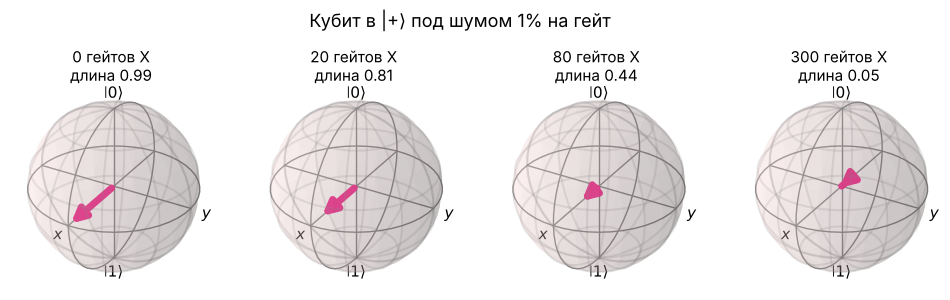

In [10]:
P_GATE = 0.01      # ✏️ ошибка на каждый X

dm_sim = AerSimulator(method="density_matrix", noise_model=make_noise(P_GATE, 0, 0))
items = []
for n_pairs in [0, 10, 40, 150]:
    q = QuantumCircuit(1)
    q.h(0)
    for _ in range(n_pairs):
        q.x(0); q.x(0)
    q.save_density_matrix()
    rho = dm_sim.run(q).result().data()["density_matrix"]     # без transpile: он бы сократил X·X
    items.append((f"{2 * n_pairs} гейтов X", bloch_vector(rho, 0)))
bloch_row(items, f"Кубит в |+⟩ под шумом {P_GATE:.0%} на гейт")

Именно это происходит в реальном процессоре со временем T2 и с каждым неидеальным гейтом. Коррекция ошибок нужна, чтобы стрелка логического кубита не укорачивалась, сколько бы гейтов мы ни сделали.

## 7. Запуск на настоящем IBM

Выключено по умолчанию, чтобы «Run All» не тратил твои бесплатные минуты. Поставь `RUN_ON_IBM = True`. `CHIP = None` — самый свободный процессор.

In [11]:
RUN_ON_IBM = False     # ✏️
CHIP = None            # ✏️ например "ibm_kingston", или None — самый свободный

if RUN_ON_IBM:
    from qiskit_ibm_runtime import QiskitRuntimeService
    from qiskit_ibm_runtime.executor_sampler import Sampler
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

    service = QiskitRuntimeService()
    backend = service.backend(CHIP) if CHIP else service.least_busy(operational=True, simulator=False)
    print("Чип:", backend.name)
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
    job = Sampler(mode=backend).run([pm.run(measured(cats))], shots=SHOTS)
    print("Job ID:", job.job_id(), "— ждём очередь...")
    real = job.result()[0].data.c.get_counts()
    print(backend.name + ":", summary(real))
    plot_counts({"идеальный": ideal, "FakeTorino": fake_counts, backend.name: real},
                "Идеал, модель и настоящий процессор")
else:
    print("Пропущено. Поставь RUN_ON_IBM = True, чтобы отправить на настоящий процессор.")

Пропущено. Поставь RUN_ON_IBM = True, чтобы отправить на настоящий процессор.


## Что попробовать

1. Раздел 1: `MODE = "independent"` — и пройди все ячейки заново. Как изменились сферы Блоха котёнка?
2. Раздел 1: `THETA = 45` — атом распадается реже. Кто чаще выживает и почему?
3. Раздел 5.2: найди такую ошибку CNOT, при которой невозможных котят становится больше 5%.
4. Раздел 5.2: поставь `P2 = 0` и подбери `P_READ`, чтобы получить картину, похожую на FakeTorino. Что важнее для этой схемы — гейты или считывание?
5. Раздел 6: какая длина стрелки получится после 1000 гейтов? Прикинь заранее, а потом проверь.